<a href="https://colab.research.google.com/github/FaizMi16/ProyekAkhir_5A_LaptopPrice/blob/main/03_varian_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Load Data & Preprocessing Dasar

In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Load data
df = pd.read_csv('laptop_price.csv', encoding='latin-1')
df.columns = df.columns.str.strip() # Rapikan nama kolom

# --- Preprocessing ---
# Bersihkan RAM
df['Ram_GB'] = pd.to_numeric(df['Ram'].astype(str).str.replace('GB', '', regex=False).str.strip(), errors='coerce')
df['Ram_GB'] = df['Ram_GB'].fillna(df['Ram_GB'].median()).astype(int)

# Bersihkan Berat
df['Weight_kg'] = pd.to_numeric(df['Weight'].astype(str).str.replace('kg', '', regex=False).str.strip(), errors='coerce')
df['Weight_kg'] = df['Weight_kg'].fillna(df['Weight_kg'].median())

# Bersihkan Memory
def parse_memory(mem):
    mem = str(mem)
    total_gb = 0.0
    for val, unit in re.findall(r'(\d+\.?\d*)\s*(GB|TB)', mem):
        v = float(val)
        total_gb += v * 1024 if unit == 'TB' else v
    return total_gb
df['Storage_GB'] = df['Memory'].apply(parse_memory)

print("Data berhasil dibersihkan. Shape:", df.shape)

Data berhasil dibersihkan. Shape: (1303, 16)


 (Metode Elbow)

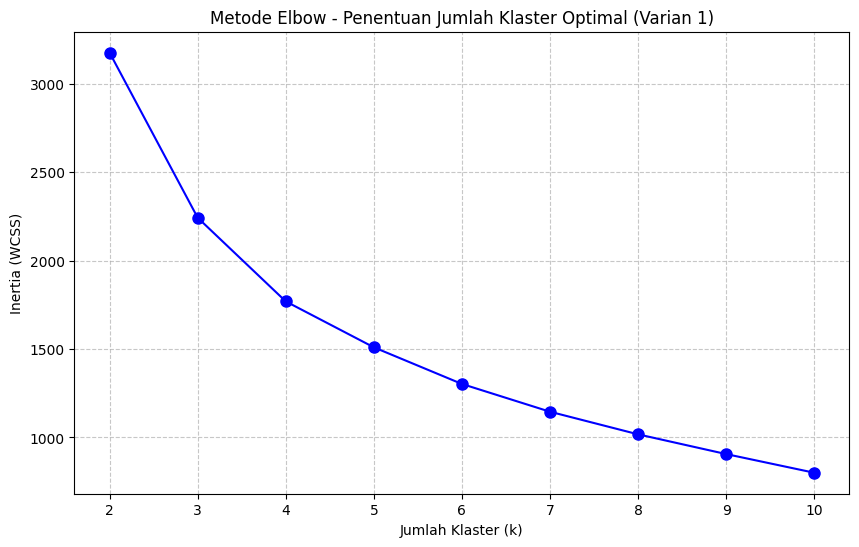

In [2]:
# Pilih fitur untuk segmentasi
fitur = ['Ram_GB', 'Inches', 'Weight_kg', 'Storage_GB']
X = df[fitur]

# Scaling (Wajib!)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Looping Metode Elbow (k=2 sampai 10)
inertia = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

# Plot Grafik
plt.figure(figsize=(10, 6))
plt.plot(K_range, inertia, marker='o', linestyle='-', color='b', markersize=8)
plt.title('Metode Elbow - Penentuan Jumlah Klaster Optimal (Varian 1)')
plt.xlabel('Jumlah Klaster (k)')
plt.ylabel('Inertia (WCSS)')
plt.xticks(K_range)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()